### 导入所需的第三方库

In [1]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import MACCSkeys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, explained_variance_score, r2_score
import random
import matplotlib.pyplot as plt
import sys
from pycaret.regression import *
import tensorflow as tf

### 数据预处理

预处理数据并计算 MACCS 指纹

In [2]:
# 读取包含 SMILES 的 CSV 文件到 DataFrame 并去重
df = pd.read_csv('logP_labels.csv')
df.drop_duplicates(keep='first', inplace=True)

# 数据预处理，化学上 logP = log10(Kow)，但数据中 Kow 已经有负数，因此已经是 logP 了
df.rename(columns={'Kow': 'logP'}, inplace=True)

# 创建一个新的列，用于存储分子指纹
df['MACCS Fingerprint'] = ''

# 遍历 SMILES列
for idx, row in df.iterrows():
    smiles = row['SMILES']

    # 将 SMILES转换为分子对象
    mol = Chem.MolFromSmiles(smiles)

    # 生成 MACCS指纹
    maccs_fp = MACCSkeys.GenMACCSKeys(mol)
    
    # 将指纹添加到 DataFrame中
    df.at[idx, 'MACCS Fingerprint'] = maccs_fp.ToBitString()
    
# 将新的 DataFrame保存到 CSV文件
df.to_excel('MACCSFingerprint_logP.xlsx', index=False)

In [3]:
# 查看除首列（序号）外的数据，确认 SMILES、logP 与指纹列已就位
df.iloc[:, 1:]

,SMILES,logP,MACCS Fingerprint
0,CC1CC2C3CCC4=CC(=O)C=CC4(C)C3(F)C(O)CC2(C)C1(O...,1.885,0000000000000000000000000010000000000000001000...
1,CC(=O)OCC(=O)C1(O)CCC2C3CCC4=CC(=O)CCC4(C)C3C(...,2.190,0000000000000000000000000010000000000000000000...
2,CC(=O)OCC(=O)C1(O)CCC2C3CCC4=CC(=O)CCC4(C)C3C(...,2.100,0000000000000000000000000010000000000000000000...
3,CCC1(c2ccccc2)C(=O)NC(=O)NC1=O,1.470,0000000000000000000000000000000000000100000100...
4,COC12C(COC(N)=O)C3=C(C(=O)C(C)=C(N)C3=O)N1CC1NC12,-0.400,0000000000000000100000110010000000000000000001...
...,...,...,...
14171,S=C(NN=C(c1ccccn1)c1ccccn1)Nc1ccccc1,1.960,0000000000000000000000000000000000000000000100...
14172,S=C=NCCCCCCCCCCc1ccccc1,6.820,0000000000000000000000000000000000000000000000...
14173,S=C=NCCCCCCCCc1ccccc1,5.810,0000000000000000000000000000000000000000000000...
14174,S=c1[nH]nc(Cn2ccc3ccccc32)n1-c1ccccc1,2.680,0000000000000000000000000000000000000010000000...


### 使用 pycaret，测试机器学习方法的表现

In [4]:
# 针对机器学习方法的数据预处理
df_copy = df.copy()

# 将 MACCS Fingerprint 字符串分解为每一位（0 或 1），并分别创建新列
maccs_columns = [f'MACCS_{i}' for i in range(167)]  # 创建167列名
maccs_values = df_copy['MACCS Fingerprint'].apply(lambda x: list(x))  # 分解成单个字符

# 将每个分解出来的字符作为新列
df_copy[maccs_columns] = pd.DataFrame(maccs_values.tolist(), index=df_copy.index)

# 删除原来的 LogP 和 MACCS Fingerprint 列，只保留 logp 和新生成的 MACCS 列
df_copy = df_copy.drop(columns=['Unnamed: 0', 'SMILES', 'MACCS Fingerprint'])

df_copy

,logP,MACCS_0,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,MACCS_8,...,MACCS_157,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166
0,1.885,0,0,0,0,0,0,0,0,0,...,1,0,1,1,0,0,1,1,1,0
1,2.190,0,0,0,0,0,0,0,0,0,...,1,0,1,1,0,0,1,1,1,0
2,2.100,0,0,0,0,0,0,0,0,0,...,1,0,1,1,0,0,1,1,1,0
3,1.470,0,0,0,0,0,0,0,0,0,...,0,1,1,1,1,1,1,1,1,0
4,-0.400,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,0,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14171,1.960,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,0,1,0
14172,6.820,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,0,1,0
14173,5.810,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,0,1,0
14174,2.680,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,0,1,0


现在我们已经将数据重新处理成为 pycaret 的输入形式了，接下来我们需要初始化 pycaret。可以看到，我们选择 `logP` 作为目标变量，其余 167 个 MACCS 指纹作为特征。我们选择 `normalize` 参数为 `True`，以便在模型训练之前对特征进行归一化处理。最后，我们设置 `session_id` 为 1，以便在后续的模型训练和评估中保持一致性。

In [5]:
# 初始化 pycaret 回归实验：指定目标列为 logP，并对特征做标准化（normalize=True）
setup(data = df_copy,
      target = 'logP',
      normalize = True,
      session_id = 1)

,Description,Value
0,Session id,1
1,Target,logP
2,Target type,Regression
3,Original data shape,"(14176, 168)"
4,Transformed data shape,"(14176, 168)"
5,Transformed train set shape,"(9923, 168)"
6,Transformed test set shape,"(4253, 168)"
7,Categorical features,167
8,Preprocess,True
9,Imputation type,simple


接下来我们调用 `compare_models()` 函数，它会比较所有可用的机器学习模型，并显示它们的平均绝对误差 (MAE) 和 R 平方 (R2) 分数。我们可以通过这些指标来评估模型的表现。

In [6]:
# 比较全部内置回归模型，按交叉验证的 MAE、R2 等指标排序输出
compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
xgboost,Extreme Gradient Boosting,0.5271,0.5306,0.7281,0.8412,0.2358,0.7067,0.5280
lightgbm,Light Gradient Boosting Machine,0.5777,0.6289,0.7926,0.8119,0.2584,0.7933,0.7000
rf,Random Forest Regressor,0.5683,0.6334,0.7954,0.8105,0.2541,0.7381,1.7650
gbr,Gradient Boosting Regressor,0.7149,0.9328,0.9656,0.7212,0.3021,1.0608,0.8810
knn,K Neighbors Regressor,0.7213,0.9677,0.9831,0.7107,0.3133,1.0250,0.4680
br,Bayesian Ridge,0.7421,1.0178,1.0086,0.6959,0.3156,1.0319,0.8120
ridge,Ridge Regression,0.7426,1.0180,1.0088,0.6958,0.3155,1.0312,0.5190
huber,Huber Regressor,0.7295,1.0405,1.0196,0.6893,0.3119,0.9668,1.5600
et,Extra Trees Regressor,0.7276,1.0697,1.0336,0.6797,0.3166,0.9301,2.3190
dt,Decision Tree Regressor,0.7511,1.1457,1.0695,0.6569,0.3256,0.9654,0.4900


Processing:   0%|          | 0/81 [00:00<?, ?it/s]

XGBRegressor(base_score=None, booster='gbtree', callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device='cpu', early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=-1,
             num_parallel_tree=None, random_state=1, ...)

可以看到，XGBoost 模型在 MAE 和 R2 分数上表现最好。因此，我们选择 XGBoost 作为我们的最终模型。

In [6]:
# 创建并训练 XGBoost 回归模型（对比实验中表现最好）
xgboost_model = create_model('xgboost')

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.5163,0.5237,0.7237,0.8381,0.2425,0.7589
1,0.5280,0.5032,0.7094,0.8442,0.2318,0.8811
2,0.5382,0.5724,0.7565,0.8206,0.2359,0.8457
3,0.5124,0.4800,0.6928,0.8631,0.2313,0.6831
4,0.5170,0.5429,0.7368,0.8389,0.2409,0.5469
5,0.5495,0.5786,0.7606,0.8271,0.2484,0.6293
6,0.5246,0.4956,0.7040,0.8452,0.2364,0.7845
7,0.5190,0.5094,0.7137,0.8636,0.2262,0.6558
8,0.5227,0.5484,0.7406,0.8347,0.2267,0.5466


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

尝试对 XGBoost 模型进行调优，以获得更好的性能。我们使用 `tune_model()` 函数，并选择 XGBoost 模型作为输入。

In [8]:
# 对 XGBoost 做自动超参调优（本例调优后性能反而下降，后续仍用原始模型）
tuned_xgboost_model = tune_model(xgboost_model)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.5661,0.6044,0.7774,0.8131,0.2633,0.7960
1,0.5873,0.6208,0.7879,0.8078,0.2674,1.0806
2,0.5803,0.6529,0.8080,0.7954,0.2564,0.9129
3,0.5664,0.6031,0.7766,0.8279,0.2638,0.8360
4,0.5931,0.6766,0.8226,0.7992,0.2654,0.6266
5,0.6123,0.6894,0.8303,0.7940,0.2751,0.6564
6,0.5869,0.6418,0.8011,0.7995,0.2644,0.7833
7,0.5613,0.6023,0.7761,0.8388,0.2466,0.7421
8,0.5807,0.6481,0.8050,0.8046,0.2474,0.5967


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


发现调优后的模型性能相较之前更差，因此我们选择原始的 XGBoost 模型作为最终模型，并我们使用 `evaluate_model()` 函数来评估调优后的模型。可以观察模型在 Residuals 和 Prediction Error 分布图中的表现，以评估模型的预测能力。

In [7]:
# 调出模型诊断界面，查看残差、预测误差、特征重要性等图表
evaluate_model(xgboost_model)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

可以调用模型的 `predict_model()` 函数来预测新数据集的 logP 值，显示在 df 对象的最后一列中。

In [10]:
# 在留出集上预测 logP，预测值会作为新列追加显示
predict_model(xgboost_model)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Extreme Gradient Boosting,0.5112,0.5129,0.7161,0.8453,0.2366,0.7163


,MACCS_0,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,MACCS_8,MACCS_9,...,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166,logP,prediction_label
12786,0,0,0,0,0,0,0,0,0,0,...,1,1,0,1,1,1,1,0,0.51,0.594965
4140,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,1,1,0,2.67,2.320235
847,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,0,2.33,2.247689
9799,0,0,0,0,0,0,0,0,0,0,...,1,0,1,1,1,1,1,0,-0.05,0.432175
6878,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,0,3.51,3.058237
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12304,0,0,0,0,0,0,0,0,0,0,...,0,1,1,1,1,0,1,0,2.99,2.568194
1185,0,0,0,0,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0.21,1.002610
6194,0,0,0,0,0,0,0,0,0,0,...,0,1,1,1,1,0,1,0,2.71,3.175382
12134,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,0,1,1,0,-0.37,-0.459845


我们使用 `finalize_model()` 函数来保存最终的模型，以便在后续的预测中使用。

In [11]:
# 用全部数据重训得到最终模型，并保存到磁盘供后续预测使用
final_model = finalize_model(xgboost_model)
save_model(final_model, 'final_xgboost_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(include=[], transformer=SimpleImputer())),
                 ('categorical_imputer',
                  TransformerWrapper(include=['MACCS_0', 'MACCS_1', 'MACCS_2',
                                              'MACCS_3', 'MACCS_4', 'MACCS_5',
                                              'MACCS_6', 'MACCS_7', 'MACCS_8',
                                              'MACCS_9', 'MACCS_10', 'MACCS_11',
                                              'MACCS_12', 'MACCS_13', 'MACCS_14',
                                              'MACCS_15', 'MACCS_...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_oneho

### 使用 PyTorch，测试深度学习方法的表现

In [12]:
# 将MACCS Fingerprint列的值转换为张量
X = torch.tensor([[int(digit) for digit in fingerprint] for fingerprint in df['MACCS Fingerprint']], dtype=torch.float32)

# 将logP列的值转换为张量
y = torch.tensor(df['logP'].values, dtype=torch.float32)

# 数据集类
class MolecularDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# 创建数据集对象
dataset = MolecularDataset(X, y)

# 划分数据集为train=70%，test=15%, val=15%
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size
train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

# 使用 DataLoader加载数据
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)
test_loader = DataLoader(test_dataset, batch_size=1) # 测试集评估

# 使用 Xavier 初始化对模型参数进行初始化
def xavier_init(m):
    if isinstance(m, nn.Linear):
        init.xavier_uniform_(m.weight)
        if m.bias is not None:
            init.constant_(m.bias, 0)

# 定义函数，获取模型参数量
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

定义前馈神经网络模型。在这里我们定义两个简单的前馈神经网络模型，分别具有 5721 和 25905 个参数。

In [ ]:
# 定义两个前馈回归网络：结构均为 3 个隐藏层 + 1 个线性输出层，仅隐藏层宽度不同
class FNN_32_8_8(nn.Module):  # 5721 参数
    def __init__(self, input_size):
        super(FNN_32_8_8, self).__init__()
        self.fc1 = nn.Linear(input_size, 32)
        self.fc2 = nn.Linear(32, 8)
        self.fc3 = nn.Linear(8, 8)
        self.fc4 = nn.Linear(8, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x
        
# 更宽的网络（128-32-8），参数量约 25905，用于对比模型容量的影响
class FNN_128_32_8(nn.Module):  # 25905 参数
    def __init__(self, input_size):
        super(FNN_128_32_8, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 32)
        self.fc3 = nn.Linear(32, 8)
        self.fc4 = nn.Linear(8, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

设置实验参数。在这里我们定义了实验编号、最大训练轮数和输入特征长度。

In [14]:
pytorch_model_names = ['FNN_32_8_8', 'FNN_128_32_8']
# 获取当前模块的全局命名空间
global_namespace = sys.modules[__name__]

experiment_num = 3
epoch_max_num = 50
input_size = 167  # MACCS Fingerprint长度

model_results_df = pd.DataFrame(columns=['Model', 'Parameters', 'Train_loss', 'Val_loss', 'Test_loss', 
                                         'Test_mae', 'Test_ev', 'Test_r2'])

开始模型的训练。在这里我们使用了早停法，当验证集上的损失在 5 轮内不再下降时，训练将停止。

In [15]:
for model_name in pytorch_model_names:
    print('Model', model_name)
    # 动态获取模型类
    model_class = getattr(global_namespace, model_name)

    # 模型最佳参数下的指标列表
    model_metrics = []

    for experiment in range(experiment_num):
        print('Experiment', experiment+1)

        # 固定随机种子
        random.seed(experiment)

        # 初始化模型、损失函数和优化器
        model = model_class(input_size=input_size)
        criterion = nn.MSELoss()
        optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-3)
        scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.5)
        
        # 提前终止参数
        patience = 5
        best_val_loss = float('inf')
        eval_train_loss = float('inf')
        best_params = None
        best_model_name = f'best_pytorch_{model_name}_exp{experiment+1}.pt'
        current_patience = 0
        
        # 计算模型参数量
        model_params_num = count_parameters(model)
        print(model_params_num)
        
        # 对模型的参数应用 Xavier 初始化
        model.apply(xavier_init)
        print('----------------------------------------------------: \n')

        # 训练模型
        for epoch in range(epoch_max_num):
            model.train()
            running_loss = 0.0
            for inputs, targets in train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets.unsqueeze(1))
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)
            epoch_loss = running_loss / len(train_loader.dataset)
        
            # 在验证集上计算损失
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for inputs, targets in val_loader:
                    outputs = model(inputs)
                    loss = criterion(outputs, targets.unsqueeze(1))
                    val_loss += loss.item() * inputs.size(0)
            val_loss /= len(val_loader.dataset)
            
            print(f'Epoch [{epoch+1}/{epoch_max_num}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}')
        
            # 检查是否需要提前终止
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                eval_train_loss = epoch_loss
                best_params = model.state_dict()
                torch.save(model.state_dict(), best_model_name)
                current_patience = 0
            else:
                # 更新学习率
                scheduler.step()
                current_patience += 1
                if current_patience >= patience:
                    print(f'Validation loss has not improved for {patience} epochs. Early stopping...')
                    break
        
        # 加载最佳模型状态字典
        model.load_state_dict(torch.load(best_model_name))
        
        # 在测试集上评估模型
        model.eval()
        test_loss = 0.0
        all_predictions = []
        all_targets = []
        
        with torch.no_grad():
            for inputs, targets in test_loader:
                outputs = model(inputs)
                loss = criterion(outputs, targets.unsqueeze(1))
                test_loss += loss.item() * inputs.size(0)
                all_predictions.append(outputs.item())
                all_targets.append(targets.item())
        
        test_loss /= len(test_loader.dataset)
        
        # 将列表转换为 NumPy 数组
        predictions = np.array(all_predictions)
        targets = np.array(all_targets)
        
        # 计算测试集上的 MSE、MAE、EV 和 R2
        test_mse = mean_squared_error(targets, predictions)
        test_mae = mean_absolute_error(targets, predictions)
        test_ev = explained_variance_score(targets, predictions)
        test_r2 = r2_score(targets, predictions)
        
        print(f'Test Loss: {test_loss:.4f}')
        print(f'Mean Squared Error: {test_mse:.4f}')
        print(f'Mean Absolute Error: {test_mae:.4f}')
        print(f'Explained Variance Score: {test_ev:.4f}')
        print(f'R-squared Score: {test_r2:.4f}')
        print('----------------------------------------------------: \n')

        # 记录当前实验的性能指标
        model_metrics.append([f'{model_name}_exp{experiment+1}', model_params_num, eval_train_loss, best_val_loss, test_loss,
                              test_mae, test_ev, test_r2])

    # 将该模型所有实验次数中最佳参数下的性能指标添加到DataFrame中
    for i, metrics in enumerate(model_metrics):
        row_name = f'pytorch_{model_name}_exp{i+1}'
        model_results_df.loc[row_name] = metrics

Model FNN_32_8_8
Experiment 1
5721
----------------------------------------------------: 

Epoch [1/50], Train Loss: 7.1765, Val Loss: 6.5140
Epoch [2/50], Train Loss: 4.4157, Val Loss: 1.6262
Epoch [3/50], Train Loss: 1.2265, Val Loss: 1.0038
Epoch [4/50], Train Loss: 0.9660, Val Loss: 0.9018
Epoch [5/50], Train Loss: 0.8638, Val Loss: 0.8390
Epoch [6/50], Train Loss: 0.7874, Val Loss: 0.7821
Epoch [7/50], Train Loss: 0.7331, Val Loss: 0.7456
Epoch [8/50], Train Loss: 0.6827, Val Loss: 0.7355
Epoch [9/50], Train Loss: 0.6518, Val Loss: 0.6980
Epoch [10/50], Train Loss: 0.6225, Val Loss: 0.6862
Epoch [11/50], Train Loss: 0.5965, Val Loss: 0.6744
Epoch [12/50], Train Loss: 0.5692, Val Loss: 0.6741
Epoch [13/50], Train Loss: 0.5489, Val Loss: 0.6627
Epoch [14/50], Train Loss: 0.5372, Val Loss: 0.6507
Epoch [15/50], Train Loss: 0.5246, Val Loss: 0.6563
Epoch [16/50], Train Loss: 0.5022, Val Loss: 0.6397
Epoch [17/50], Train Loss: 0.4853, Val Loss: 0.6379
Epoch [18/50], Train Loss: 0.4779,

查看并保存训练结果。

In [16]:
# 将各模型各次实验的指标导出为 Excel，并在 Notebook 中展示汇总表
model_results_df.to_excel("PyTorch_models_results.xlsx")
model_results_df

,Model,Parameters,Train_loss,Val_loss,Test_loss,Test_mae,Test_ev,Test_r2
pytorch_FNN_32_8_8_exp1,FNN_32_8_8_exp1,5721,0.436943,0.618427,0.643191,0.580245,0.811495,0.811030
pytorch_FNN_32_8_8_exp2,FNN_32_8_8_exp2,5721,0.534779,0.638593,0.694622,0.606398,0.795932,0.795919
pytorch_FNN_32_8_8_exp3,FNN_32_8_8_exp3,5721,0.515036,0.650733,0.664092,0.593842,0.804978,0.804889
pytorch_FNN_128_32_8_exp1,FNN_128_32_8_exp1,25905,0.405219,0.568549,0.602426,0.559426,0.823038,0.823007
pytorch_FNN_128_32_8_exp2,FNN_128_32_8_exp2,25905,0.278828,0.515220,0.559278,0.540649,0.835767,0.835684
pytorch_FNN_128_32_8_exp3,FNN_128_32_8_exp3,25905,0.339651,0.556361,0.581643,0.548438,0.829216,0.829113


绘图，更加明显的查看训练效果。可以看到，随着参数量的增加，深度学习模型的效果在这里逐渐升高，相较 XGBoost，能够达到更好的效果。

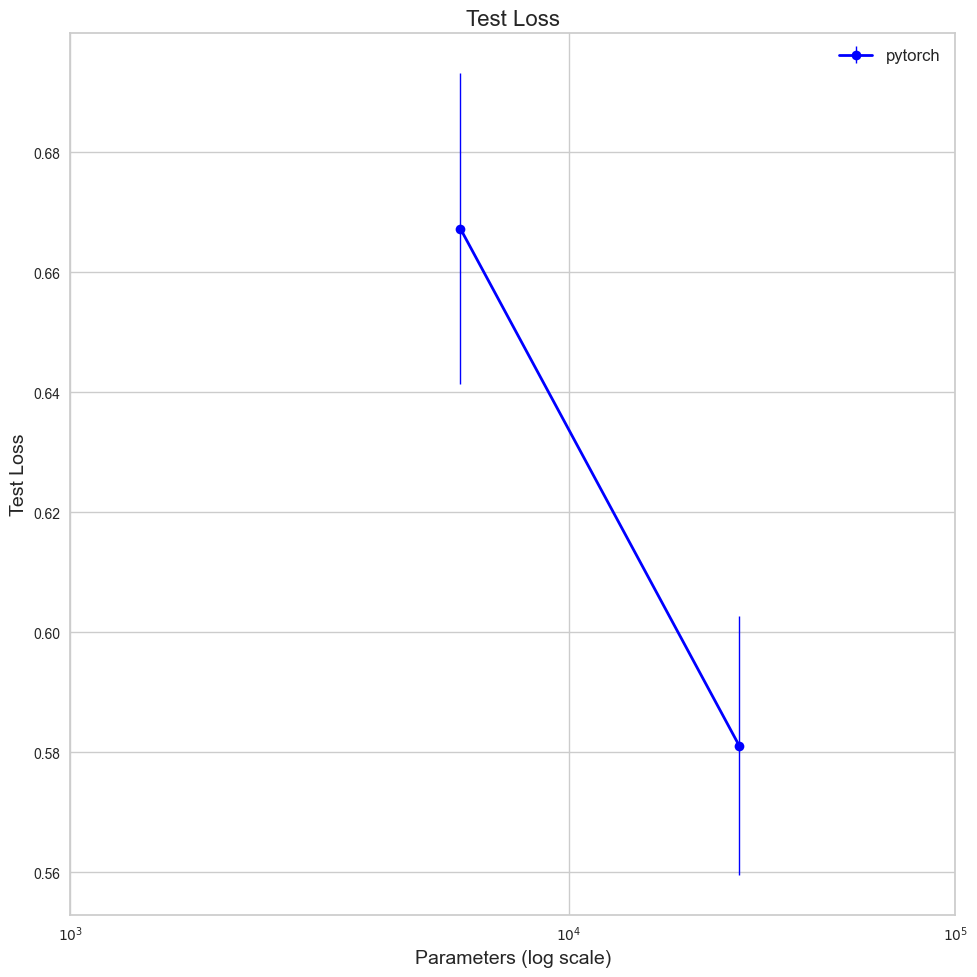

In [ ]:
# 将表格数据按模型名称和实验次数分组
model_results_df['Experiment'] = model_results_df['Model'].apply(lambda x: x.split('_exp')[0])
model_results_df['Experiment_Num'] = model_results_df['Model'].apply(lambda x: x.split('_exp')[1])

# 定义模型类别和颜色
model_categories = {
    'pytorch': pytorch_model_names,
}

colors = {'pytorch': 'blue'}

# 计算每个参数下测试准确率的平均值和标准差
mean_std_data = model_results_df.groupby(['Experiment', 'Parameters'])['Test_loss'].agg(['mean', 'std']).reset_index()

# 绘制折线图
fig, ax = plt.subplots(figsize=(10, 10))

for category, models in model_categories.items():
    # 提取符合当前类别的数据
    data = mean_std_data[mean_std_data['Experiment'].isin(models)]
    
    # 对数据按参数进行排序
    data_sorted = data.sort_values(by='Parameters')
    
    positions = np.log10(data_sorted['Parameters'])
    
    # 计算平均值和标准差
    means = data_sorted['mean']
    stds = data_sorted['std']
    
    # 绘制折线及误差棒，并调整粗细和格式
    ax.errorbar(
        positions, 
        means, 
        yerr=stds, 
        fmt='-o', 
        color=colors[category], 
        label=category,
        linewidth=2,        # 控制折线的粗细
        elinewidth=1,       # 控制误差棒的粗细
        capsize=5,          # 控制误差棒顶部的封顶形状
    )

# 设置字体大小
plt.rcParams.update({'font.size': 14})

ax.set_title('Test Loss', fontsize=16)
ax.set_xlabel('Parameters (log scale)', fontsize=14)
ax.set_xscale('log')
ax.set_ylabel('Test Loss', fontsize=14)

# 设置X轴刻度标签
ax.set_xticks([3, 4, 5])
ax.set_xticklabels([r'$10^3$', r'$10^4$', r'$10^5$'])
ax.set_xlim(left=3, right=5)

# 添加图例
ax.legend(loc='best', fontsize=12)

plt.tight_layout()
plt.show()

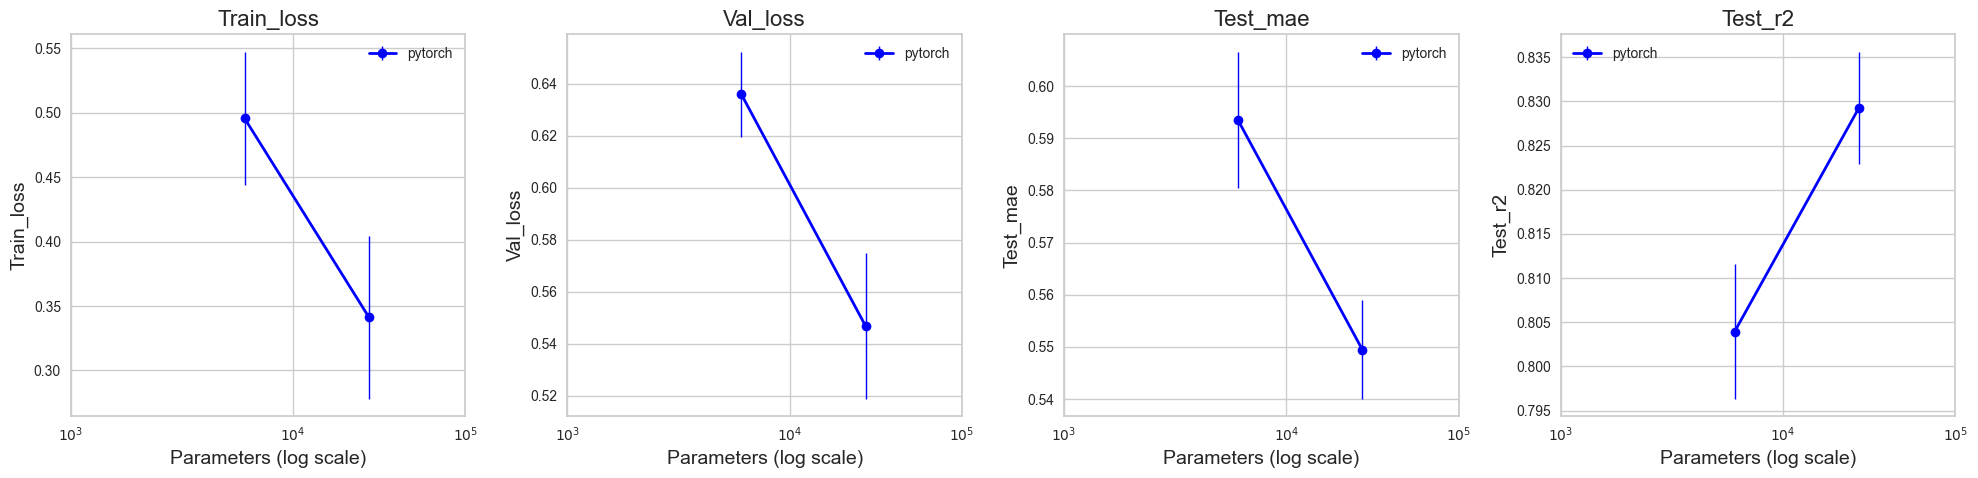

In [18]:
# 确定需要绘制的指标
metrics = ['Train_loss', 'Val_loss', 'Test_mae', 'Test_r2']

# 计算每个参数下各指标的平均值和标准差
mean_std_data = model_results_df.groupby(['Experiment', 'Parameters'])[metrics].agg(['mean', 'std']).reset_index()

# 绘制折线图
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    for category, models in model_categories.items():
        # 提取符合当前类别的数据
        data = mean_std_data[mean_std_data['Experiment'].isin(models)]
        
        # 对数据按参数进行排序
        data_sorted = data.sort_values(by='Parameters')
        
        positions = np.log10(data_sorted['Parameters'])
        
        # 计算平均值和标准差
        means = data_sorted[metric]['mean']
        stds = data_sorted[metric]['std']
        
        # 绘制折线及误差棒，并调整粗细和格式
        ax.errorbar(
            positions, 
            means, 
            yerr=stds, 
            fmt='-o', 
            color=colors[category], 
            label=category,
            linewidth=2,        # 控制折线的粗细
            elinewidth=1,       # 控制误差棒的粗细
            capsize=5,          # 控制误差棒顶部的封顶形状
        )
    
    # 设置图的标题和坐标轴标签
    ax.set_title(metric, fontsize=16)
    ax.set_xlabel('Parameters (log scale)', fontsize=14)
    ax.set_xscale('log')
    ax.set_ylabel(metric, fontsize=14)
    
    # 设置X轴刻度标签
    ax.set_xticks([3, 4, 5])
    ax.set_xticklabels([r'$10^3$', r'$10^4$', r'$10^5$'])
    ax.set_xlim(left=3, right=5)
    
    # 添加图例
    ax.legend(loc='best', fontsize=10)

# 调整子图之间的间距
plt.tight_layout()
plt.show()

### 查看 y的数据分布，直观评估模型效果

可以看到，大约 0.5 的 MAE 基本就相当于下图中偏离一个 bar 的宽度。

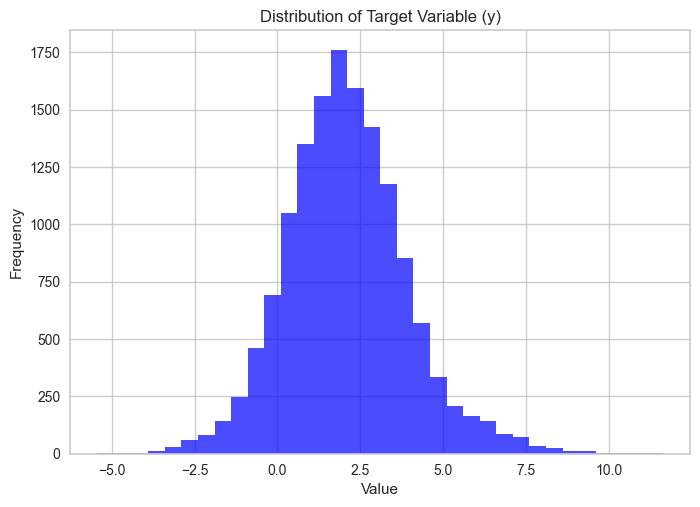

In [19]:
# 取出目标变量 logP 的数值（张量则先转为 numpy 数组）
y_values = y.numpy() if isinstance(y, torch.Tensor) else y
# 以 0.5 为区间宽度构造直方图边界
bin_edges = np.arange(min(y_values), max(y_values) + 0.5, 0.5)

# 绘制直方图
plt.hist(y_values, bins=bin_edges, color='blue', alpha=0.7)
plt.title('Distribution of Target Variable (y)')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

### *使用 TensorFlow

将 PyTorch 框架换成 TensorFlow 同样可以达到相同的效果，以下是一个采用学习率衰减的 TensorFlow 模型，效果比早停法略差，在此不做赘述。

In [ ]:
# 将MACCS Fingerprint列的值转换为张量
X = np.array([[int(digit) for digit in fingerprint] for fingerprint in df['MACCS Fingerprint']], dtype=np.float32)

# 将logP列的值转换为张量
y = np.array(df['logP'].values, dtype=np.float32)

# 划分数据集为train=70%，test=15%, val=15%
train_size = int(0.7 * len(X))
val_size = int(0.15 * len(X))
test_size = len(X) - train_size - val_size

X_train, X_val, X_test = X[:train_size], X[train_size:train_size + val_size], X[train_size + val_size:]
y_train, y_val, y_test = y[:train_size], y[train_size:train_size + val_size], y[train_size + val_size:]

# 将数据转化为TensorFlow Dataset对象
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train)).batch(64)
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(64)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(1)  # 测试集评估

# 定义前馈神经网络模型
class FNN_32_8_8(tf.keras.Model):  # 5721 参数
    def __init__(self, input_size):
        super(FNN_32_8_8, self).__init__()
        self.fc1 = tf.keras.layers.Dense(32, activation='relu', input_shape=(input_size,))
        self.fc2 = tf.keras.layers.Dense(8, activation='relu')
        self.fc3 = tf.keras.layers.Dense(8, activation='relu')
        self.fc4 = tf.keras.layers.Dense(1)

    def call(self, x):
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)
        x = self.fc4(x)
        return x

class FNN_128_32_8(tf.keras.Model):  # 25905 参数
    def __init__(self, input_size):
        super(FNN_128_32_8, self).__init__()
        self.fc1 = tf.keras.layers.Dense(128, activation='relu', input_shape=(input_size,))
        self.fc2 = tf.keras.layers.Dense(32, activation='relu')
        self.fc3 = tf.keras.layers.Dense(8, activation='relu')
        self.fc4 = tf.keras.layers.Dense(1)

    def call(self, x):
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)
        x = self.fc4(x)
        return x

# 选择模型
tf_model_names = ['FNN_32_8_8', 'FNN_128_32_8']
input_size = 167  # MACCS Fingerprint长度

# 实验设置
experiment_num = 3
epoch_max_num = 50


In [31]:
# 记录模型性能
model_results_df = pd.DataFrame(columns=['Model', 'Parameters', 'Train_loss', 'Val_loss', 'Test_loss', 
                                         'Test_mae', 'Test_ev', 'Test_r2'])

# 创建模型实例并训练
for model_name in tf_model_names:
    print(f"Model {model_name}")
    model_metrics = []

    for experiment in range(experiment_num):
        print(f"Experiment {experiment + 1}")
        
        # 固定随机种子
        np.random.seed(experiment)

        # 初始化模型
        if model_name == 'FNN_32_8_8':
            model = FNN_32_8_8(input_size)
        elif model_name == 'FNN_128_32_8':
            model = FNN_128_32_8(input_size)
        
        model.build((None, input_size))
        
        # 编译模型
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                      loss='mean_squared_error', metrics=['mae'])

        # 早停回调函数
        early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        
        # 学习率调度器
        def lr_schedule(epoch):
            return 0.001 * 0.8 ** epoch
        
        lr_scheduler = tf.keras.callbacks.LearningRateScheduler(lr_schedule)

        # 训练模型
        history = model.fit(train_dataset, epochs=epoch_max_num, validation_data=val_dataset, 
                            callbacks=[early_stopping, lr_scheduler])

        # 在测试集上评估模型
        test_loss, test_mae = model.evaluate(test_dataset)
        
        # 获取预测结果
        predictions = model.predict(test_dataset)
        targets = y_test  # 真正的目标值

        # 计算性能指标
        test_mse = mean_squared_error(targets, predictions)
        test_mae = mean_absolute_error(targets, predictions)
        test_ev = explained_variance_score(targets, predictions)
        test_r2 = r2_score(targets, predictions)

        print(f'Test Loss: {test_loss:.4f}')
        print(f'Mean Squared Error: {test_mse:.4f}')
        print(f'Mean Absolute Error: {test_mae:.4f}')
        print(f'Explained Variance Score: {test_ev:.4f}')
        print(f'R-squared Score: {test_r2:.4f}')
        print('----------------------------------------------------: \n')

        # 记录当前实验的性能指标
        model_metrics.append([f'{model_name}_exp{experiment + 1}', model.count_params(), 
                              history.history['loss'][-1], history.history['val_loss'][-1], 
                              test_loss, test_mae, test_ev, test_r2])

    # 将该模型所有实验次数中最佳参数下的性能指标添加到DataFrame中
    for i, metrics in enumerate(model_metrics):
        row_name = f'tensorflow_{model_name}_exp{i+1}'
        model_results_df.loc[row_name] = metrics

Model FNN_32_8_8
Experiment 1
Epoch 1/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5.7111 - mae: 1.8680 - val_loss: 1.6044 - val_mae: 0.9442 - learning_rate: 0.0010
Epoch 2/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.4078 - mae: 0.8676 - val_loss: 1.2207 - val_mae: 0.8212 - learning_rate: 8.0000e-04
Epoch 3/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0855 - mae: 0.7510 - val_loss: 1.1151 - val_mae: 0.7933 - learning_rate: 6.4000e-04
Epoch 4/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9973 - mae: 0.7171 - val_loss: 1.1043 - val_mae: 0.7996 - learning_rate: 5.1200e-04
Epoch 5/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8849 - mae: 0.6813 - val_loss: 1.1140 - val_mae: 0.7977 - learning_rate: 4.0960e-04
Epoch 6/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8475 - mae: 0.6686 - val_loss: 1.0646 - val_mae: 0.7823 - learning_rate: 3.2768e-04
Epoch 7/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8152 - mae: 0.6592 - val_loss: 1.082